<a href="https://colab.research.google.com/github/Imanita7/AI-for-Science-and-Engineering/blob/main/Student_performance_ml_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Building my first machine learning model
##Project Overview
This assignment uses the Student Performance dataset to build and compare two supervised machine-learning classification models. I aim to identify students who may be at risk of poor academic performance using relevant academic, behavioural and demographic features.

The models will be trained and tested using a train-test split, evaluated with appropriate classification metrics and compared to determine their performance in identifying students at risk.

In [9]:
!pip install -q ucimlrepo
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Importing the dataset
student_performance = fetch_ucirepo(id = 320)

df = pd.concat(
    [
        student_performance.data.features,
        student_performance.data.targets
    ],
    axis = 1
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [10]:
#The binary target
df["at_risk"] = (df["G3"] < 10).astype(int)

#Separating into x(features) and y(target)
x = df.drop(columns = ["G3", "at_risk"])
y = df["at_risk"]

print("Input features:", x.shape[1])
print("Target distribution:")
print(y.map({0: "Not at risk", 1: "At risk"}).value_counts())

Input features: 32
Target distribution:
at_risk
Not at risk    549
At risk        100
Name: count, dtype: int64


In [11]:
#Splitting the dataset into training and testing sets
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2, #20% of the data is used for testing
    random_state = 42, #Makes the split reproducible
    stratify = y #Preserves the proportions of the two target classes in both sets
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

Training samples: 519
Testing samples: 130


In [12]:
#Preparing the data
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

#Identify numerical and categorical columns
numeric_features = x.select_dtypes(include = "number").columns.tolist()
categorical_features = x.select_dtypes(
    exclude = "number"
).columns.tolist()

#Preprocess numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

#Preprocess categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown = "ignore"))
])

#Combining processing steps
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

#Define two supervised learning models
models = {
    "Logistic Regression": LogisticRegression(max_iter = 1000),
    "Random Forest": RandomForestClassifier(
        n_estimators = 100,
        random_state = 42,
        class_weight = "balanced"
    )
}

#Train each model
trained_models = {}

for name, model in models.items():
  pipeline = Pipeline([
      ("preprocessor", preprocessor),
      ("classifier", model)
  ])

  pipeline.fit(x_train, y_train)
  trained_models[name] = pipeline

  print(name, "trained successfully.")

Logistic Regression trained successfully.
Random Forest trained successfully.



Logistic Regression
              precision    recall  f1-score   support

 Not at risk       0.96      0.95      0.95       110
     At risk       0.73      0.80      0.76        20

    accuracy                           0.92       130
   macro avg       0.85      0.87      0.86       130
weighted avg       0.93      0.92      0.92       130



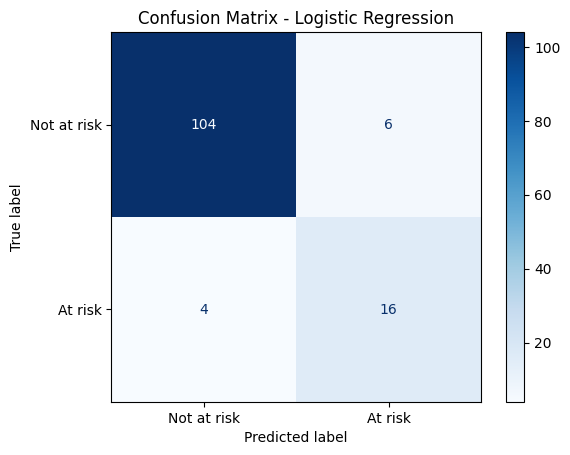

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.923,0.727,0.8,0.762



Random Forest
              precision    recall  f1-score   support

 Not at risk       0.91      0.97      0.94       110
     At risk       0.75      0.45      0.56        20

    accuracy                           0.89       130
   macro avg       0.83      0.71      0.75       130
weighted avg       0.88      0.89      0.88       130



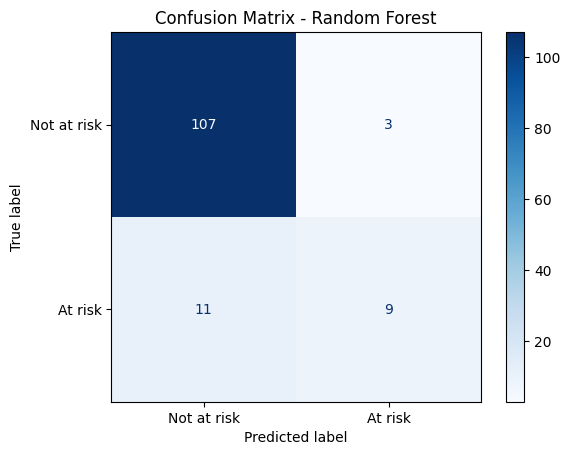

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.923,0.727,0.80,0.762
Random Forest,0.892,0.750,0.45,0.562


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

results = []

for name, model in trained_models.items():
  #Predict on unseen test data
  y_pred = model.predict(x_test)

  #Calculate performance metrics
  results.append({
      "Model": name,
      "Accuracy": accuracy_score(y_test, y_pred),
      "Precision": precision_score(
          y_test, y_pred, zero_division = 0
      ),
      "Recall": recall_score(
          y_test, y_pred, zero_division = 0
      ),
      "F1 Score": f1_score(
          y_test, y_pred, zero_division = 0
      )
  })

  print(f"\n{name}")
  print(classification_report(
      y_test,
      y_pred,
      labels = [0, 1],
      target_names = ["Not at risk", "At risk"],
      zero_division = 0
  ))

  ConfusionMatrixDisplay.from_predictions(
      y_test,
      y_pred,
      labels = [0, 1],
      display_labels = ["Not at risk", "At risk"],
      cmap = "Blues"
  )
  plt.title(f"Confusion Matrix - {name}")
  plt.show()

  results_df = pd.DataFrame(results).set_index("Model")
  display(results_df.round(3))

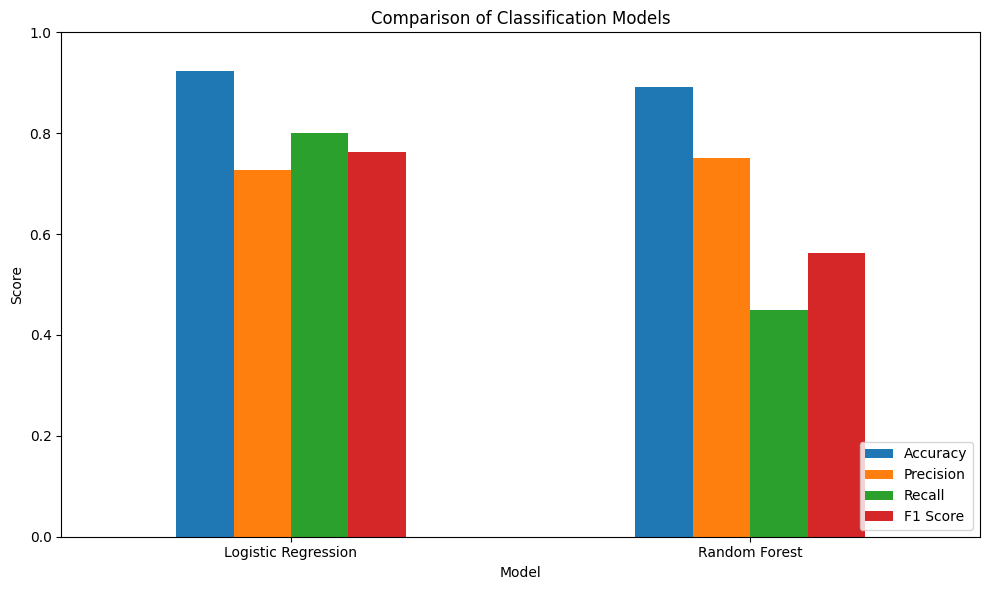

Model with the highest F1 score: Logistic Regression


In [14]:
#Compare the models using a bar chart
results_df.plot(
    kind = "bar",
    figsize = (10, 6),
    ylim = (0, 1)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation = 0)
plt.legend(loc = "lower right")
plt.tight_layout()
plt.show()

#Identify the model with the highest F1 score
best_model = results_df["F1 Score"].idxmax()

print("Model with the highest F1 score:", best_model)

##Model evaluation and comparison
The two supervised classification models, Logistic Regression and Random Fores, were trained to classify students as At Risk or Not at Risk. Both models were evaluated using accuracy, precision, recall and F1 score on the test dataset.

The result show that Logistic Regression achieved a higher F1 score of 0.7619, compared to 0.5625 for Random Forest. Logistic Regression also achieved a higher recall of 0.80, compared to 0.45 for Random Forest, for the At risk class.

This shows that Logistic Regression achieved a better balance between precision and recall and identified a larger proportion of students who were actually at risk. Since the aim was to identify as many students as possible who are at risk and require additional academic support, the Logistic Regression seems to be the more suitable model as per these results.

However, further evaluation would be needed to determine how well the model performs on new student data.

In [15]:
#Confirming the results
print("F1 Score comparison:")
print(results_df["F1 Score"].sort_values(ascending = False))

print("\nRecall comparison:")
print(results_df["Recall"].sort_values(ascending = False))

F1 Score comparison:
Model
Logistic Regression    0.761905
Random Forest          0.562500
Name: F1 Score, dtype: float64

Recall comparison:
Model
Logistic Regression    0.80
Random Forest          0.45
Name: Recall, dtype: float64
